# Лабораторная работа №4
## Исследование алгоритма случайного леса

**Цель работы:** исследовать Random Forest для классификации и регрессии, сравнить baseline и улучшенные модели `scikit-learn`, самостоятельно реализовать алгоритм ансамблирования на основе CART и оценить качество моделей

Используются те же наборы данных и разбиение, что и в предыдущих лабораторных:
- **Breast Cancer Wisconsin (Diagnostic)** - бинарная классификация (`malignant` / `benign`)
- **Wine Quality Red** - регрессия оценки качества вина

Случайный лес объединяет множество деревьев, обученных на bootstrap-выборках. При построении каждого узла рассматривается случайное подмножество признаков. Это снижает корреляцию между деревьями и обычно уменьшает дисперсию ансамбля

## 1. Постановка задач и метрики

Для классификации используются Accuracy, F1-score (binary и macro), ROC-AUC, Recall и F1 для класса `malignant`, а также confusion matrix. Для регрессии используются MAE, RMSE и R^2

Для воспроизводимости фиксируется `RANDOM_STATE`. Данные делятся на train/test в пропорции 80/20; тестовая часть не используется при подборе гиперпараметров

Импортируются библиотеки для подготовки данных, обучения случайного леса, кросс-валидации, оценки метрик и визуализации

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, recall_score,
    mean_absolute_error, mean_squared_error, r2_score,
    confusion_matrix, classification_report, RocCurveDisplay
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.precision", 4)

Загружаются Breast Cancer Wisconsin из `sklearn` и Wine Quality Red из UCI. Проверяются размеры выборок и распределения целевых переменных

In [2]:
cancer = load_breast_cancer()
X_clf = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_clf = pd.Series(cancer.target, name="target")  # 0 = malignant, 1 = benign

url_wine = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
wine = pd.read_csv(url_wine, sep=";")
X_reg = wine.drop(columns="quality")
y_reg = wine["quality"]

print("Breast Cancer:", X_clf.shape, y_clf.value_counts().sort_index().to_dict())
print("Wine Quality:", X_reg.shape, y_reg.value_counts().sort_index().to_dict())

Breast Cancer: (569, 30) {0: 212, 1: 357}
Wine Quality: (1599, 11) {3: 10, 4: 53, 5: 681, 6: 638, 7: 199, 8: 18}


Визуализируется распределение классов и целевой переменной регрессии. Это помогает оценить баланс классов и дискретность оценок качества вина

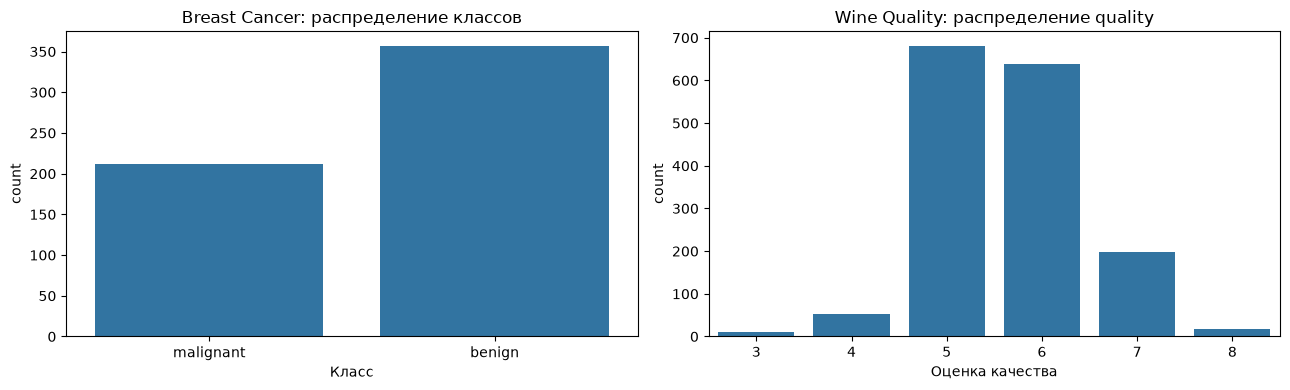

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=y_clf.map({0: "malignant", 1: "benign"}), ax=axes[0])
axes[0].set_title("Breast Cancer: распределение классов")
axes[0].set_xlabel("Класс")
sns.countplot(x=y_reg, ax=axes[1])
axes[1].set_title("Wine Quality: распределение quality")
axes[1].set_xlabel("Оценка качества")
plt.tight_layout()
plt.show()

Разделяем данные на обучающую и тестовую выборки. Для классификации используем стратификацию. Обе модели обучаются на одинаковых разбиениях, что обеспечиваеет сопоставимость результатов с ЛР1-ЛР3

In [4]:
X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
)
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)
print("Classification:", X_clf_train.shape, X_clf_test.shape)
print("Regression:", X_reg_train.shape, X_reg_test.shape)

Classification: (455, 30) (114, 30)
Regression: (1279, 11) (320, 11)


## 2. Создание baseline и оценка качества

### 2.1. RandomForestClassifier - baseline

Обучается классификатор случайного леса с параметрами `scikit-learn` по умолчанию. Для воспроизводимости фиксируется random_state. Помимо стандартных метрик отдельно оценивается качество распознавания класса `malignant`

In [5]:
rf_clf_base = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
rf_clf_base.fit(X_clf_train, y_clf_train)

y_clf_pred_base = rf_clf_base.predict(X_clf_test)
y_clf_proba_base = rf_clf_base.predict_proba(X_clf_test)[:, 1]

acc_clf_base = accuracy_score(y_clf_test, y_clf_pred_base)
f1_clf_base = f1_score(y_clf_test, y_clf_pred_base)
f1_macro_clf_base = f1_score(y_clf_test, y_clf_pred_base, average="macro")
roc_clf_base = roc_auc_score(y_clf_test, y_clf_proba_base)
recall_mal_base = recall_score(y_clf_test, y_clf_pred_base, pos_label=0)
f1_mal_base = f1_score(y_clf_test, y_clf_pred_base, pos_label=0)

print(f"Accuracy: {acc_clf_base:.4f}")
print(f"F1 binary: {f1_clf_base:.4f}")
print(f"F1 macro: {f1_macro_clf_base:.4f}")
print(f"ROC-AUC: {roc_clf_base:.4f}")
print(f"Recall malignant: {recall_mal_base:.4f}")
print(f"F1 malignant: {f1_mal_base:.4f}")
print(classification_report(y_clf_test, y_clf_pred_base, target_names=["malignant", "benign"]))

Accuracy: 0.9561
F1 binary: 0.9655
F1 macro: 0.9526
ROC-AUC: 0.9937
Recall malignant: 0.9286
F1 malignant: 0.9398
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



### 2.2. RandomForestRegressor - baseline

Обучается регрессор случайного леса с настройками по умолчанию. Качество оценивается по MAE, RMSE и R^2

In [6]:
rf_reg_base = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)
rf_reg_base.fit(X_reg_train, y_reg_train)
y_reg_pred_base = rf_reg_base.predict(X_reg_test)

mae_reg_base = mean_absolute_error(y_reg_test, y_reg_pred_base)
rmse_reg_base = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_base))
r2_reg_base = r2_score(y_reg_test, y_reg_pred_base)

print(f"MAE: {mae_reg_base:.4f}")
print(f"RMSE: {rmse_reg_base:.4f}")
print(f"R^2: {r2_reg_base:.4f}")

MAE: 0.4224
RMSE: 0.5489
R^2: 0.5390


Диагностика baseline: матрица ошибок для классификации, график фактических и предсказанных значений регрессии, а также число деревьев и параметры ансамбля

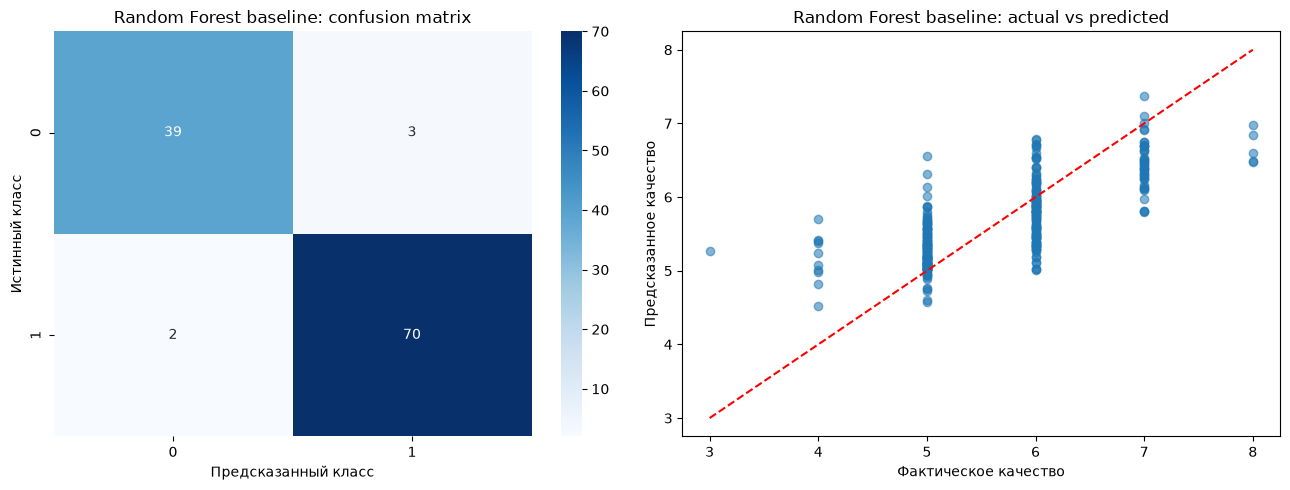

n_estimators classifier: 100
n_estimators regressor: 100


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(confusion_matrix(y_clf_test, y_clf_pred_base), annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Random Forest baseline: confusion matrix")
axes[0].set_xlabel("Предсказанный класс")
axes[0].set_ylabel("Истинный класс")

axes[1].scatter(y_reg_test, y_reg_pred_base, alpha=0.55)
lims = [min(y_reg_test.min(), y_reg_pred_base.min()), max(y_reg_test.max(), y_reg_pred_base.max())]
axes[1].plot(lims, lims, "r--")
axes[1].set_title("Random Forest baseline: actual vs predicted")
axes[1].set_xlabel("Фактическое качество")
axes[1].set_ylabel("Предсказанное качество")
plt.tight_layout()
plt.show()

print("n_estimators classifier:", len(rf_clf_base.estimators_))
print("n_estimators regressor:", len(rf_reg_base.estimators_))

## 3. Улучшение baseline

### 3.1. Гипотезы улучшения

**Классификация и регрессия:**
1. Увеличение числа деревьев (`n_estimators`) может стабилизировать ансамбль, хотя после некоторого значения прирост качества становится небольшим
2. Ограничение глубины (`max_depth`) и увеличение `min_samples_leaf` могут уменьшить переобучение отдельных деревьев
3. Изменение `max_features` влияет на разнообразие деревьев и корреляцию между ними
4. Для классификации оптимизируем F1 macro, чтобы учитывать оба класса; для регрессии - MAE, менее чувствительную к отдельным большим ошибкам, чем MSE

Проверим гипотезы через `GridSearchCV` с 5-fold CV

Подбираются параметры классификатора: количество деревьев, число признаков, рассматриваемых при разбиении, глубина и минимальный размер листа. Для оценки используется StratifiedKFold

In [8]:
param_grid_clf = {
    "n_estimators": [100, 200],
    "max_features": ["sqrt", 0.5],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid_clf = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=param_grid_clf,
    scoring="f1_macro",
    cv=cv_clf,
    n_jobs=-1,
    verbose=1
)
grid_clf.fit(X_clf_train, y_clf_train)
print("Best params:", grid_clf.best_params_)
print("Best CV F1 macro:", grid_clf.best_score_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV F1 macro: 0.9602693026481022


Подбираются параметры регрессора. Критерий оптимизации - MAE; используется обычная 5-fold кросс-валидация

In [9]:
param_grid_reg = {
    "n_estimators": [100, 200],
    "max_features": [1.0, 0.7],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 4]
}
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid_reg = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=param_grid_reg,
    scoring="neg_mean_absolute_error",
    cv=cv_reg,
    n_jobs=-1,
    verbose=1
)
grid_reg.fit(X_reg_train, y_reg_train)
print("Best params:", grid_reg.best_params_)
print("Best CV MAE:", -grid_reg.best_score_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params: {'max_depth': 20, 'max_features': 1.0, 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV MAE: 0.43083359676155447


Оцениваем лучшие sklearn-модели на отложенных тестовых выборках. Здесь тестовые данные используются только для финальной оценки

In [10]:
rf_clf_improved = grid_clf.best_estimator_
y_clf_pred_improved = rf_clf_improved.predict(X_clf_test)
y_clf_proba_improved = rf_clf_improved.predict_proba(X_clf_test)[:, 1]

acc_clf_improved = accuracy_score(y_clf_test, y_clf_pred_improved)
f1_clf_improved = f1_score(y_clf_test, y_clf_pred_improved)
f1_macro_clf_improved = f1_score(y_clf_test, y_clf_pred_improved, average="macro")
roc_clf_improved = roc_auc_score(y_clf_test, y_clf_proba_improved)
recall_mal_improved = recall_score(y_clf_test, y_clf_pred_improved, pos_label=0)
f1_mal_improved = f1_score(y_clf_test, y_clf_pred_improved, pos_label=0)

rf_reg_improved = grid_reg.best_estimator_
y_reg_pred_improved = rf_reg_improved.predict(X_reg_test)
mae_reg_improved = mean_absolute_error(y_reg_test, y_reg_pred_improved)
rmse_reg_improved = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_improved))
r2_reg_improved = r2_score(y_reg_test, y_reg_pred_improved)

print("CLASSIFICATION")
print(f"Accuracy={acc_clf_improved:.4f}, F1={f1_clf_improved:.4f}, F1 macro={f1_macro_clf_improved:.4f}")
print(f"ROC-AUC={roc_clf_improved:.4f}, Recall malignant={recall_mal_improved:.4f}, F1 malignant={f1_mal_improved:.4f}")
print("\nREGRESSION")
print(f"MAE={mae_reg_improved:.4f}, RMSE={rmse_reg_improved:.4f}, R^2={r2_reg_improved:.4f}")

CLASSIFICATION
Accuracy=0.9561, F1=0.9655, F1 macro=0.9526
ROC-AUC=0.9937, Recall malignant=0.9286, F1 malignant=0.9398

REGRESSION
MAE=0.4224, RMSE=0.5487, R^2=0.5392


Сравниваем baseline и improved по одним и тем же тестовым метрикам. Так можно увидеть, какие гипотезы улучшения подтвердились

In [11]:
clf_baseline_vs_improved = pd.DataFrame([
    ["Random Forest baseline", acc_clf_base, f1_clf_base, f1_macro_clf_base, roc_clf_base, recall_mal_base, f1_mal_base],
    ["Random Forest improved", acc_clf_improved, f1_clf_improved, f1_macro_clf_improved, roc_clf_improved, recall_mal_improved, f1_mal_improved]
], columns=["Модель", "Accuracy", "F1 binary", "F1 macro", "ROC-AUC", "Recall malignant", "F1 malignant"])
display(clf_baseline_vs_improved)

reg_baseline_vs_improved = pd.DataFrame([
    ["Random Forest baseline", mae_reg_base, rmse_reg_base, r2_reg_base],
    ["Random Forest improved", mae_reg_improved, rmse_reg_improved, r2_reg_improved]
], columns=["Модель", "MAE", "RMSE", "R^2"])
display(reg_baseline_vs_improved)

,Модель,Accuracy,F1 binary,F1 macro,ROC-AUC,Recall malignant,F1 malignant
0,Random Forest baseline,0.9561,0.9655,0.9526,0.9937,0.9286,0.9398
1,Random Forest improved,0.9561,0.9655,0.9526,0.9937,0.9286,0.9398


,Модель,MAE,RMSE,R^2
0,Random Forest baseline,0.4224,0.5489,0.5390
1,Random Forest improved,0.4224,0.5487,0.5392


ROC-кривые показывают качество ранжирования классов, а график регрессии позволяет сравнить ошибки baseline и improved визуально

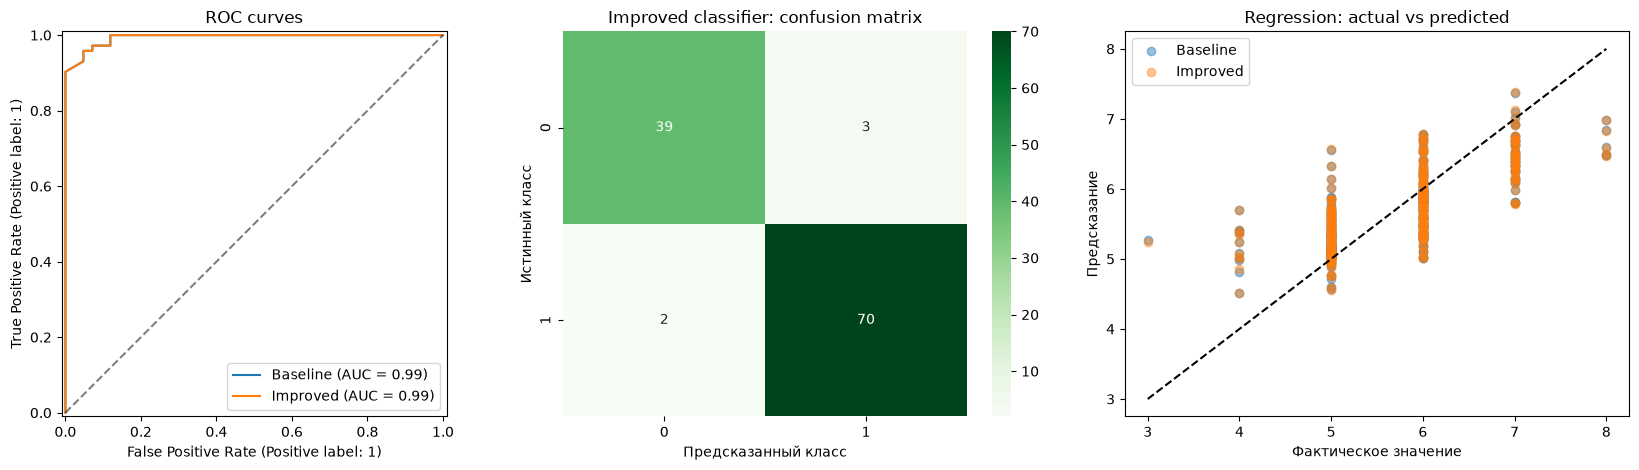

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_base, name="Baseline", ax=axes[0])
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_improved, name="Improved", ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("ROC curves")

sns.heatmap(confusion_matrix(y_clf_test, y_clf_pred_improved), annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("Improved classifier: confusion matrix")
axes[1].set_xlabel("Предсказанный класс")
axes[1].set_ylabel("Истинный класс")

axes[2].scatter(y_reg_test, y_reg_pred_base, alpha=0.45, label="Baseline")
axes[2].scatter(y_reg_test, y_reg_pred_improved, alpha=0.45, label="Improved")
lims = [min(y_reg_test.min(), y_reg_pred_base.min(), y_reg_pred_improved.min()),
        max(y_reg_test.max(), y_reg_pred_base.max(), y_reg_pred_improved.max())]
axes[2].plot(lims, lims, "k--")
axes[2].set_title("Regression: actual vs predicted")
axes[2].set_xlabel("Фактическое значение")
axes[2].set_ylabel("Предсказание")
axes[2].legend()
plt.tight_layout()
plt.show()

## 4. Самостоятельная имплементация Random Forest

Ниже реализуется собственный ансамбль случайного леса. Для каждого дерева:
1. формируется bootstrap-выборка объектов с возвращением
2. при построении каждого узла случайно выбирается подмножество признаков (`max_features`)
3. дерево CART выбирает лучший порог среди выбранных признаков
4. для классификации вероятности усредняются по деревьям, итоговый класс выбирается по максимальной вероятности
5. для регрессии усредняются численные прогнозы деревьев

Это учебная реализация без готовых `RandomForestClassifier` / `RandomForestRegressor`. Для базового дерева используется собственный CART, а не sklearn

Определяем CART-дерево с рандомизацией признаков на каждом узле. (Тут код основан на реализации дерева из ЛР3; ключевое отличие - при каждом поиске разбиения рассматривается случайное подмножество признаков)

In [13]:
class MyRandomTree:
    def __init__(self, task="classification", criterion=None, max_depth=None,
                 min_samples_split=2, min_samples_leaf=1, max_features="sqrt",
                 random_state=None):
        self.task = task
        self.criterion = criterion or ("gini" if task == "classification" else "squared_error")
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.rng = np.random.default_rng(random_state)
        self.root_ = None

    def _n_features_to_sample(self, n_features):
        if self.max_features is None or self.max_features == 1.0:
            return n_features
        if self.max_features == "sqrt":
            return max(1, int(np.sqrt(n_features)))
        if self.max_features == "log2":
            return max(1, int(np.log2(n_features)))
        if isinstance(self.max_features, float):
            return max(1, int(self.max_features * n_features))
        return min(n_features, int(self.max_features))

    def _impurity(self, y):
        if self.task == "classification":
            counts = np.bincount(y, minlength=len(self.classes_))
            p = counts[counts > 0] / len(y)
            if self.criterion == "entropy":
                return -np.sum(p * np.log2(p))
            return 1.0 - np.sum(p ** 2)
        return np.var(y)

    def _best_split(self, X, y):
        n_samples, n_features = X.shape
        parent_impurity = self._impurity(y)
        best, best_score = None, parent_impurity
        feature_candidates = self.rng.choice(
            n_features, size=self._n_features_to_sample(n_features), replace=False
        )

        for feature in feature_candidates:
            order = np.argsort(X[:, feature], kind="mergesort")
            xs, ys = X[order, feature], y[order]
            positions = np.flatnonzero(xs[:-1] < xs[1:]) + 1
            positions = positions[
                (positions >= self.min_samples_leaf) &
                ((n_samples - positions) >= self.min_samples_leaf)
            ]
            if len(positions) == 0:
                continue

            left_n = positions.astype(float)
            right_n = (n_samples - positions).astype(float)

            if self.task == "classification":
                one_hot = np.eye(len(self.classes_), dtype=float)[ys]
                cumulative = np.cumsum(one_hot, axis=0)
                total = cumulative[-1]
                lc, rc = cumulative[positions - 1], total - cumulative[positions - 1]

                if self.criterion == "entropy":
                    def entropy(counts):
                        probs = counts / counts.sum(axis=1, keepdims=True)
                        terms = np.zeros_like(probs)
                        mask = probs > 0
                        terms[mask] = probs[mask] * np.log2(probs[mask])
                        return -terms.sum(axis=1)
                    li, ri = entropy(lc), entropy(rc)
                else:
                    lp, rp = lc / left_n[:, None], rc / right_n[:, None]
                    li, ri = 1 - (lp ** 2).sum(axis=1), 1 - (rp ** 2).sum(axis=1)
                scores = (left_n * li + right_n * ri) / n_samples
            else:
                cs, cq = np.cumsum(ys), np.cumsum(ys ** 2)
                total_s, total_q = cs[-1], cq[-1]
                ls, lq = cs[positions - 1], cq[positions - 1]
                rs, rq = total_s - ls, total_q - lq
                left_sse = np.maximum(lq - ls ** 2 / left_n, 0)
                right_sse = np.maximum(rq - rs ** 2 / right_n, 0)
                scores = (left_sse + right_sse) / n_samples

            idx = int(np.argmin(scores))
            if scores[idx] < best_score - 1e-12:
                pos = int(positions[idx])
                best_score = float(scores[idx])
                best = (int(feature), float((xs[pos - 1] + xs[pos]) / 2))
        return best

    def _build(self, X, y, depth):
        if self.task == "classification":
            counts = np.bincount(y, minlength=len(self.classes_))
            prediction, value = int(np.argmax(counts)), counts / counts.sum()
        else:
            prediction, value = float(np.mean(y)), float(np.mean(y))

        node = {"prediction": prediction, "value": value}
        stop = (len(y) < self.min_samples_split or len(np.unique(y)) == 1 or
                (self.max_depth is not None and depth >= self.max_depth))
        if stop:
            return node

        split = self._best_split(X, y)
        if split is None:
            return node
        feature, threshold = split
        left = X[:, feature] <= threshold
        right = ~left
        if left.sum() < self.min_samples_leaf or right.sum() < self.min_samples_leaf:
            return node
        node.update({
            "feature": feature, "threshold": threshold,
            "left": self._build(X[left], y[left], depth + 1),
            "right": self._build(X[right], y[right], depth + 1)
        })
        return node

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        if self.task == "classification":
            self.classes_, encoded = np.unique(y, return_inverse=True)
            y_fit = encoded.astype(int)
        else:
            y_fit = y.astype(float)
        self.n_features_in_ = X.shape[1]
        self.root_ = self._build(X, y_fit, 0)
        return self

    def _leaf(self, row, node):
        while "feature" in node:
            node = node["left"] if row[node["feature"]] <= node["threshold"] else node["right"]
        return node

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        leaves = [self._leaf(row, self.root_) for row in X]
        if self.task == "classification":
            return self.classes_[np.array([leaf["prediction"] for leaf in leaves], dtype=int)]
        return np.array([leaf["prediction"] for leaf in leaves], dtype=float)

    def predict_proba(self, X):
        if self.task != "classification":
            raise AttributeError("predict_proba доступен только для классификации")
        X = np.asarray(X, dtype=float)
        return np.vstack([self._leaf(row, self.root_)["value"] for row in X])

Реализуем класс `MyRandomForest`: bootstrap-выборка для каждого дерева, независимый генератор случайных чисел и агрегирование предсказаний. Для классификации классы кодируются единообразно, вероятности усредняются по деревьям

In [14]:
class MyRandomForest:
    def __init__(self, task="classification", n_estimators=50, max_features="sqrt",
                 max_depth=None, min_samples_split=2, min_samples_leaf=1,
                 criterion=None, random_state=42):
        if task not in ("classification", "regression"):
            raise ValueError("task должен быть classification или regression")
        self.task = task
        self.n_estimators = n_estimators
        self.max_features = max_features
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.criterion = criterion
        self.random_state = random_state
        self.estimators_ = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        rng = np.random.default_rng(self.random_state)
        n = len(X)

        if self.task == "classification":
            self.classes_ = np.unique(y)
        self.estimators_ = []

        for i in range(self.n_estimators):
            sample_idx = rng.integers(0, n, size=n)
            tree = MyRandomTree(
                task=self.task, criterion=self.criterion,
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                min_samples_leaf=self.min_samples_leaf,
                max_features=self.max_features,
                random_state=int(rng.integers(0, 2**31 - 1))
            )
            tree.fit(X[sample_idx], y[sample_idx])
            self.estimators_.append(tree)
        self.n_features_in_ = X.shape[1]
        return self

    def predict_proba(self, X):
        if self.task != "classification":
            raise AttributeError("predict_proba доступен только для классификации")
        probabilities = np.mean([tree.predict_proba(X) for tree in self.estimators_], axis=0)
        return probabilities

    def predict(self, X):
        if self.task == "classification":
            proba = self.predict_proba(X)
            return self.classes_[np.argmax(proba, axis=1)]
        predictions = np.vstack([tree.predict(X) for tree in self.estimators_])
        return predictions.mean(axis=0)

### 4.1. Проверка собственной реализации на небольшом примере

Перед обучением на полных датасетах проверяем, что обе версии модели обучаются, возвращают предсказания ожидаемой формы, а классификатор выдаёт вероятности, сумма которых равна единице

In [15]:
X_demo = np.array([[0, 0], [0, 1], [1, 0], [1, 1], [0.1, 0.2], [0.9, 0.8]], dtype=float)
y_demo_clf = np.array([0, 0, 1, 1, 0, 1])
y_demo_reg = np.array([0.0, 0.2, 0.8, 1.0, 0.1, 0.9])

demo_clf = MyRandomForest(task="classification", n_estimators=5, random_state=1).fit(X_demo, y_demo_clf)
demo_reg = MyRandomForest(task="regression", n_estimators=5, random_state=1).fit(X_demo, y_demo_reg)
print("Classifier predictions:", demo_clf.predict(X_demo))
print("Classifier probabilities sum:", demo_clf.predict_proba(X_demo).sum(axis=1))
print("Regressor predictions:", demo_reg.predict(X_demo))

Classifier predictions: [0 0 1 1 0 1]
Classifier probabilities sum: [1. 1. 1. 1. 1. 1.]
Regressor predictions: [0.13666667 0.28333333 0.71333333 0.94       0.10333333 0.92      ]


### 4.2. Собственные модели без улучшений (raw)

Обучаем собственные леса с базовыми параметрами. Число деревьев задаём умеренным, чтобы учебная реализация с Python-циклами выполнялась за разумное время. Важно: это raw-вариант без настройки по результатам GridSearchCV

In [16]:
my_rf_clf_raw = MyRandomForest(
    task="classification", n_estimators=30, random_state=RANDOM_STATE
).fit(X_clf_train, y_clf_train)
y_clf_pred_my_raw = my_rf_clf_raw.predict(X_clf_test)
y_clf_proba_my_raw = my_rf_clf_raw.predict_proba(X_clf_test)[:, 1]

my_rf_reg_raw = MyRandomForest(
    task="regression", n_estimators=30, random_state=RANDOM_STATE
).fit(X_reg_train, y_reg_train)
y_reg_pred_my_raw = my_rf_reg_raw.predict(X_reg_test)

my_clf_raw_metrics = {
    "Accuracy": accuracy_score(y_clf_test, y_clf_pred_my_raw),
    "F1 binary": f1_score(y_clf_test, y_clf_pred_my_raw),
    "F1 macro": f1_score(y_clf_test, y_clf_pred_my_raw, average="macro"),
    "ROC-AUC": roc_auc_score(y_clf_test, y_clf_proba_my_raw),
    "Recall malignant": recall_score(y_clf_test, y_clf_pred_my_raw, pos_label=0),
    "F1 malignant": f1_score(y_clf_test, y_clf_pred_my_raw, pos_label=0)
}
my_reg_raw_metrics = {
    "MAE": mean_absolute_error(y_reg_test, y_reg_pred_my_raw),
    "RMSE": np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_my_raw)),
    "R²": r2_score(y_reg_test, y_reg_pred_my_raw)
}
print("MyRandomForest raw - classification:", my_clf_raw_metrics)
print("MyRandomForest raw - regression:", my_reg_raw_metrics)

MyRandomForest raw - classification: {'Accuracy': 0.9385964912280702, 'F1 binary': 0.951048951048951, 'F1 macro': 0.9343480049362403, 'ROC-AUC': 0.9947089947089948, 'Recall malignant': 0.9285714285714286, 'F1 malignant': 0.9176470588235294}
MyRandomForest raw - regression: {'MAE': 0.4290625, 'RMSE': np.float64(0.5625432082170321), 'R²': 0.515758188589522}


### 4.3. Собственные модели с техниками улучшенного baseline

Переносим найденные GridSearchCV параметры на собственную реализацию. `n_estimators` и `max_features` задают ансамбль, а `max_depth` и `min_samples_leaf` регулируют сложность базовых деревьев. Количество деревьев ограничиваем 30 для разумного времени выполнения учебной реализации

In [17]:
best_clf_params = grid_clf.best_params_.copy()
best_reg_params = grid_reg.best_params_.copy()

my_rf_clf_improved = MyRandomForest(
    task="classification",
    n_estimators=30,
    max_features=best_clf_params["max_features"],
    max_depth=best_clf_params["max_depth"],
    min_samples_leaf=best_clf_params["min_samples_leaf"],
    random_state=RANDOM_STATE
).fit(X_clf_train, y_clf_train)

my_rf_reg_improved = MyRandomForest(
    task="regression",
    n_estimators=30,
    max_features=best_reg_params["max_features"],
    max_depth=best_reg_params["max_depth"],
    min_samples_leaf=best_reg_params["min_samples_leaf"],
    random_state=RANDOM_STATE
).fit(X_reg_train, y_reg_train)

y_clf_pred_my_improved = my_rf_clf_improved.predict(X_clf_test)
y_clf_proba_my_improved = my_rf_clf_improved.predict_proba(X_clf_test)[:, 1]
y_reg_pred_my_improved = my_rf_reg_improved.predict(X_reg_test)

print("MyRandomForest improved — classification")
print("Accuracy:", accuracy_score(y_clf_test, y_clf_pred_my_improved))
print("F1 macro:", f1_score(y_clf_test, y_clf_pred_my_improved, average="macro"))
print("ROC-AUC:", roc_auc_score(y_clf_test, y_clf_proba_my_improved))
print("Recall malignant:", recall_score(y_clf_test, y_clf_pred_my_improved, pos_label=0))
print("\nMyRandomForest improved — regression")
print("MAE:", mean_absolute_error(y_reg_test, y_reg_pred_my_improved))
print("RMSE:", np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_my_improved)))
print("R^2:", r2_score(y_reg_test, y_reg_pred_my_improved))

MyRandomForest improved — classification
Accuracy: 0.9385964912280702
F1 macro: 0.9343480049362403
ROC-AUC: 0.9947089947089948
Recall malignant: 0.9285714285714286

MyRandomForest improved — regression
MAE: 0.4286844858125334
RMSE: 0.5613376525432218
R^2: 0.5178314690795733


## 5. Сравнение всех моделей

Сводные таблицы позволяют сравнить sklearn baseline, sklearn improved, собственный Random Forest raw и собственный Random Forest improved на одних и тех же тестовых выборках

In [18]:
classification_results = pd.DataFrame([
    ["sklearn baseline", acc_clf_base, f1_clf_base, f1_macro_clf_base, roc_clf_base, recall_mal_base, f1_mal_base],
    ["sklearn improved", acc_clf_improved, f1_clf_improved, f1_macro_clf_improved, roc_clf_improved, recall_mal_improved, f1_mal_improved],
    ["MyRandomForest raw", my_clf_raw_metrics["Accuracy"], my_clf_raw_metrics["F1 binary"], my_clf_raw_metrics["F1 macro"], my_clf_raw_metrics["ROC-AUC"], my_clf_raw_metrics["Recall malignant"], my_clf_raw_metrics["F1 malignant"]],
    ["MyRandomForest improved", accuracy_score(y_clf_test, y_clf_pred_my_improved), f1_score(y_clf_test, y_clf_pred_my_improved), f1_score(y_clf_test, y_clf_pred_my_improved, average="macro"), roc_auc_score(y_clf_test, y_clf_proba_my_improved), recall_score(y_clf_test, y_clf_pred_my_improved, pos_label=0), f1_score(y_clf_test, y_clf_pred_my_improved, pos_label=0)]
], columns=["Модель", "Accuracy", "F1 binary", "F1 macro", "ROC-AUC", "Recall malignant", "F1 malignant"])
display(classification_results)

regression_results = pd.DataFrame([
    ["sklearn baseline", mae_reg_base, rmse_reg_base, r2_reg_base],
    ["sklearn improved", mae_reg_improved, rmse_reg_improved, r2_reg_improved],
    ["MyRandomForest raw", my_reg_raw_metrics["MAE"], my_reg_raw_metrics["RMSE"], my_reg_raw_metrics["R²"]],
    ["MyRandomForest improved", mean_absolute_error(y_reg_test, y_reg_pred_my_improved), np.sqrt(mean_squared_error(y_reg_test, y_reg_pred_my_improved)), r2_score(y_reg_test, y_reg_pred_my_improved)]
], columns=["Модель", "MAE", "RMSE", "R^2"])
display(regression_results)

,Модель,Accuracy,F1 binary,F1 macro,ROC-AUC,Recall malignant,F1 malignant
0,sklearn baseline,0.9561,0.9655,0.9526,0.9937,0.9286,0.9398
1,sklearn improved,0.9561,0.9655,0.9526,0.9937,0.9286,0.9398
2,MyRandomForest raw,0.9386,0.9510,0.9343,0.9947,0.9286,0.9176
3,MyRandomForest improved,0.9386,0.9510,0.9343,0.9947,0.9286,0.9176


,Модель,MAE,RMSE,R^2
0,sklearn baseline,0.4224,0.5489,0.5390
1,sklearn improved,0.4224,0.5487,0.5392
2,MyRandomForest raw,0.4291,0.5625,0.5158
3,MyRandomForest improved,0.4287,0.5613,0.5178


Сравниваем ROC-кривые четырёх классификаторов и ошибки регрессии. Это помогает оценить не только отдельные числа, но и общую картину качества

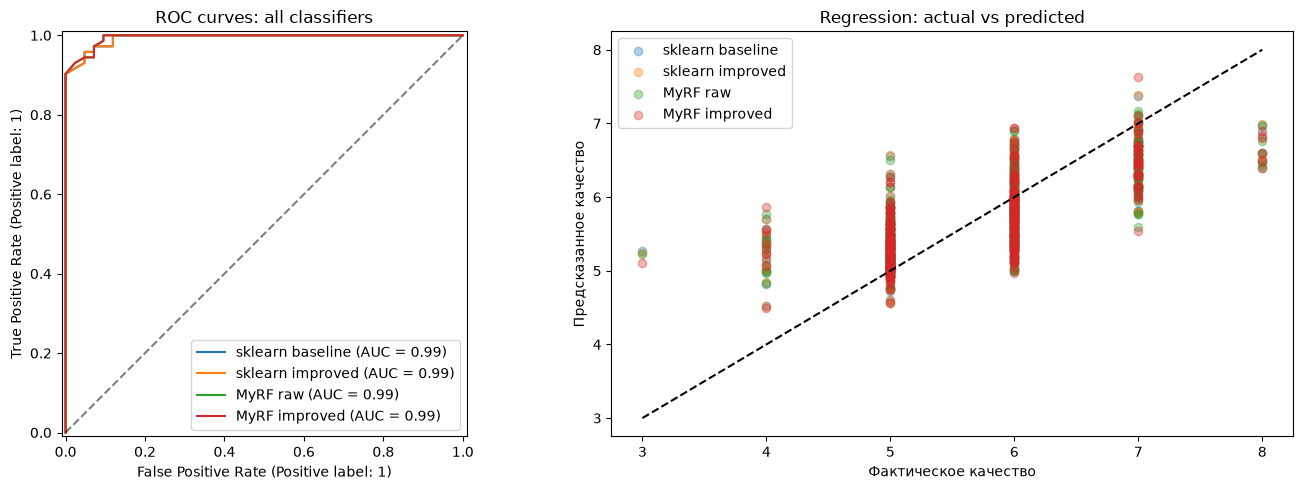

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_base, name="sklearn baseline", ax=axes[0])
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_improved, name="sklearn improved", ax=axes[0])
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_my_raw, name="MyRF raw", ax=axes[0])
RocCurveDisplay.from_predictions(y_clf_test, y_clf_proba_my_improved, name="MyRF improved", ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("ROC curves: all classifiers")

axes[1].scatter(y_reg_test, y_reg_pred_base, alpha=0.35, label="sklearn baseline")
axes[1].scatter(y_reg_test, y_reg_pred_improved, alpha=0.35, label="sklearn improved")
axes[1].scatter(y_reg_test, y_reg_pred_my_raw, alpha=0.35, label="MyRF raw")
axes[1].scatter(y_reg_test, y_reg_pred_my_improved, alpha=0.35, label="MyRF improved")
lims = [min(y_reg_test.min(), y_reg_pred_base.min(), y_reg_pred_improved.min(), y_reg_pred_my_raw.min(), y_reg_pred_my_improved.min()),
        max(y_reg_test.max(), y_reg_pred_base.max(), y_reg_pred_improved.max(), y_reg_pred_my_raw.max(), y_reg_pred_my_improved.max())]
axes[1].plot(lims, lims, "k--")
axes[1].set_title("Regression: actual vs predicted")
axes[1].set_xlabel("Фактическое качество")
axes[1].set_ylabel("Предсказанное качество")
axes[1].legend()
plt.tight_layout()
plt.show()

### 5.1. Важность признаков

Случайный лес агрегирует важности признаков базовых деревьев. В sklearn доступен атрибут `feature_importances_`, основанный на суммарном уменьшении impurity. Эти значения полезны для анализа модели, но не доказывают причинно-следственную связь и могут быть смещены в пользу признаков с большим числом возможных порогов

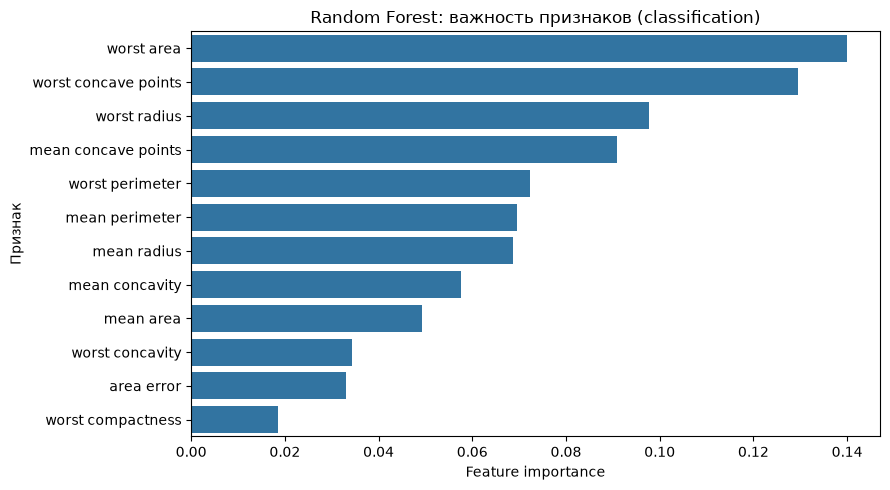

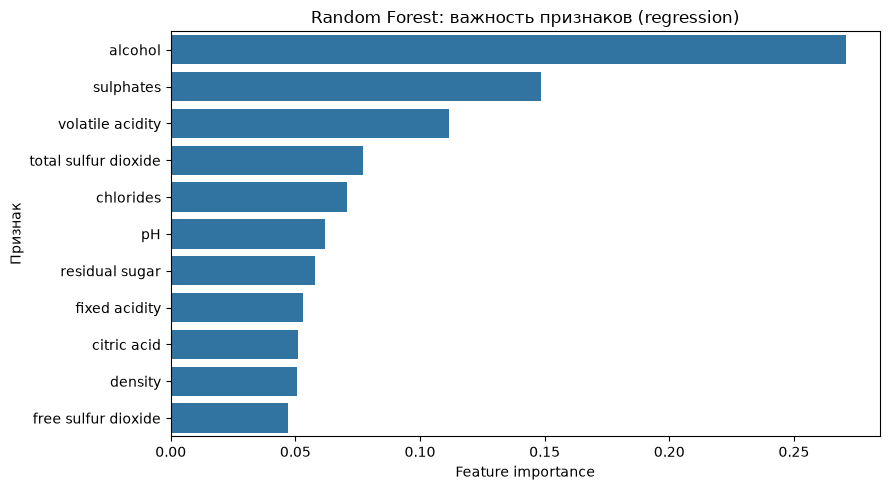

In [20]:
def plot_feature_importance(model, feature_names, title, top_n=12):
    values = pd.Series(model.feature_importances_, index=feature_names).sort_values(ascending=False).head(top_n)
    plt.figure(figsize=(9, 5))
    sns.barplot(x=values.values, y=values.index)
    plt.title(title)
    plt.xlabel("Feature importance")
    plt.ylabel("Признак")
    plt.tight_layout()
    plt.show()

plot_feature_importance(rf_clf_improved, X_clf.columns, "Random Forest: важность признаков (classification)")
plot_feature_importance(rf_reg_improved, X_reg.columns, "Random Forest: важность признаков (regression)")

## 6. Выводы

В лабораторной работе был исследован алгоритм случайного леса для решения задач классификации и регрессии. Эксперименты проводились на Breast Cancer Wisconsin (569 объектов, 30 признаков) и Wine Quality Red (1599 объектов, 11 признаков). Использовалось разбиение train/test в пропорции 80/20 с `random_state=42`; для классификации применялась стратификация. Подбор гиперпараметров выполнялся только на обучающей выборке с помощью 5-fold кросс-валидации

### 6.1. Классификация

Базовый `RandomForestClassifier` показал Accuracy = 0.9561, F1 binary = 0.9655, F1 macro = 0.9526 и ROC-AUC = 0.9937. Recall для класса `malignant` составил 0.9286, F1 этого класса - 0.9398

GridSearchCV выбрал параметры `n_estimators=100`, `max_features='sqrt'`, `max_depth=None`, `min_samples_leaf=1`; лучший средний результат кросс-валидации по F1 macro составил 0.9603. Выбранная конфигурация совпала с конфигурацией baseline, поэтому на тестовой выборке метрики baseline и improved оказались одинаковыми. Следовательно, в данном эксперименте подбор параметров не дал измеримого улучшения классификации, но подтвердил, что исходные настройки уже подходят для выбранного разбиения и набора данных

Самостоятельная реализация `MyRandomForest` показала Accuracy = 0.9386, F1 binary = 0.9510, F1 macro = 0.9343 и ROC-AUC = 0.9947. Recall класса `malignant` совпал со sklearn-моделью и равен 0.9286, однако F1 для `malignant` оказался ниже (0.9176 против 0.9398). Таким образом, собственная реализация воспроизводит высокое качество классификации и близка к sklearn, но по пороговым метрикам немного уступает ей. Более высокий ROC-AUC собственной модели не означает, что она лучше по всем критериям: ROC-AUC оценивает ранжирование объектов по вероятности, а Accuracy и F1 - качество конкретных классификационных решений

### 6.2. Регрессия

Базовый `RandomForestRegressor` получил MAE = 0.4224, RMSE = 0.5489 и R^2 = 0.5390. GridSearchCV выбрал `n_estimators=100`, `max_features=1.0`, `max_depth=20`, `min_samples_leaf=1`; средний MAE на кросс-валидации составил 0.4308. На тестовой выборке MAE осталась 0.4224, RMSE незначительно снизилась до 0.5487, а R^2 вырос до 0.5392. Улучшение очень небольшое, поэтому нельзя говорить о существенном приросте качества

Собственная реализация `MyRandomForest` без настройки показала MAE = 0.4291, RMSE = 0.5625 и R^2 = 0.5158. После переноса параметров, найденных GridSearchCV для sklearn, результаты немного улучшились: MAE = 0.4287, RMSE = 0.5613, R^2 = 0.5178. При этом собственная модель осталась несколько хуже sklearn по всем трём метрикам

### 6.3. Проверка собственной реализации

В реализации `MyRandomForest` самостоятельно реализованы bootstrap-выборки, случайный выбор подмножества признаков на каждом узле, построение CART-деревьев и агрегирование предсказаний. На демонстрационном примере проверены обучение классификатора и регрессора, форма предсказаний и нормировка вероятностей классов (сумма вероятностей для каждого объекта равна 1). На основных наборах данных собственная реализация успешно обучилась и выдала результаты, близкие к sklearn

### 6.4. Общий вывод

Случайный лес показал высокое качество на задаче классификации Breast Cancer и умеренное качество на задаче регрессии Wine Quality. Для классификации базовая конфигурация sklearn уже оказалась удачной, поэтому GridSearchCV не изменил выбранные параметры и тестовые метрики. Для регрессии настройка дала лишь небольшое улучшение. Самостоятельная реализация продемонстрировала корректную работу основных механизмов Random Forest и конкурентные, хотя несколько более слабые результаты по сравнению со sklearn

Результаты подтверждают, что ансамблирование деревьев позволяет получать устойчивые и качественные модели без масштабирования признаков. При этом выводы относятся к одному фиксированному разбиению train/test; для более надёжного сравнения моделей полезно дополнительно оценить разброс метрик на нескольких разбиениях или с помощью повторной кросс-валидации. В задаче медицинской классификации особенно важно отдельно контролировать Recall класса `malignant`, поскольку пропуск злокачественного случая имеет высокую практическую цену